# 03. Guia das bases dos modelos

Etapa 3 do fluxo: `01_download.ipynb` → `02_serie_modelos.ipynb` → **`03_guia_bases_modelos.ipynb`** → entradas de cada modelo (`04_entradas_modelo1_gp.ipynb`, `05_entradas_modelo2_rgp.ipynb`, `06_entradas_modelo3_gplvm.ipynb`) → notebooks dos modelos (`07`–`09`).

Este notebook lê a `serie` salva pelo `02_serie_modelos.ipynb` e mostra, para os três modelos do trabalho (GP Student‑t, RGP‑t e Bayesian GPLVM), como montar a entrada de cada um, o formato da saída e como as saídas serão avaliadas. É o guia de referência para quem implementa um modelo.

| Seção | Conteúdo |
|---|---|
| 1 | Carregar os módulos |
| 2 | Argumentos e funcionalidades das funções |
| 3 | Tabela base compartilhada (`serie`) |
| 4 | Entrada de cada modelo, bloco a bloco (`X_train`, `Y_train`, `X_val`, …) |
| 5 | Formato da saída dos modelos |
| 6 | Métricas: previsão (reconstrução) e detecção de anomalias |

Execute as células em ordem. Nenhuma célula consulta a API: tudo vem dos arquivos locais.

## 1. Carregar os módulos

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def find_project_root(start: Path) -> Path:
    for folder in (start.resolve(), *start.resolve().parents):
        if (folder / "src" / "main.py").is_file() and (folder / "data" / "usgs").is_dir():
            return folder
    raise FileNotFoundError("Não encontrei src/main.py e data/usgs. Abra o notebook na pasta do projeto.")

PROJECT_ROOT = find_project_root(Path.cwd())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import USGS, EXPORT_ROOT
from src.catalog import export_dataset
from src.main import build_model_dataset, default_download_config
from src.download import load_selected
from src.model_data import PROBLEM_QUALIFIERS, SelectionConfig, SplitConfig, split_summary
from src.model_inputs import gp_inputs, rgp_inputs, gplvm_inputs, select_split, windows_to_days
from src.evaluation import (OUTPUT_COLUMNS, check_output, reconstruction_metrics, conformal_factor,
                            apply_conformal, threshold_from_calibration, detection_metrics,
                            detection_by_group)

print(f"Projeto: {PROJECT_ROOT}")
print(f"Parâmetro: {USGS.parameter_code} | estatística: {USGS.statistic_id} | "
      f"período: {USGS.date_start} a {USGS.date_end}")

Projeto: C:\Users\aliss\OneDrive\Repositorios\usgs_streamflow
Parâmetro: 00060 | estatística: 00003 | período: 2010-01-01 a 2025-12-31


## 2. Argumentos e funcionalidades das funções

### 2.1 Função principal

| Função | O que faz | Retorno |
|---|---|---|
| `build_model_dataset(selection, splits, config=None)` (`src/main.py`) | lê os Parquets gerados pelo `01_download.ipynb` (`data/usgs/raw/parquets/`, período do `.env`), completa o calendário diário, cria os rótulos, separa os blocos, escolhe as estações, esconde os pontos de avaliação e normaliza | `(serie, stats)` |
| `prepare_model_dataset(full, selection, splits)` (`src/model_data.py`) | o mesmo, a partir de uma tabela diária já carregada (saída de `complete_daily_calendar`) | `(serie, stats)` |
| `split_summary(serie)` | resumo por bloco: período, dias visíveis, escondidos, anomalias e provisórios | tabela |

`serie` é a tabela compartilhada (seção 3). Neste fluxo, ela é montada e salva uma única vez no `02_serie_modelos.ipynb`; os outros notebooks só a leem. `stats` guarda média e desvio de cada estação, para voltar de `y` para ft³/s.

### 2.2 `SelectionConfig`: quais estações entram

Todas as condições são calculadas **só no bloco de treino**, para não olhar o futuro.

| Argumento | Padrão | O que faz | Exemplos |
|---|---|---|---|
| `n_sensors` | 10 | número de estações sorteadas entre as que passam nos filtros | `1` = caso univariado; `5` a `20` = caso multivariado |
| `min_completeness` | 0.95 | fração mínima de dias com valor no treino | `0.90` aceita mais lacunas |
| `max_zero_frac` | 0.05 | fração máxima de dias com vazão zero (exclui rios intermitentes) | `0.0` = só rios perenes |
| `candidates` | `None` | restringe o sorteio a uma lista de IDs | estações vizinhas de `pares_nldi_*_150km.csv` |
| `seed` | 42 | semente do sorteio das estações | mude para outra amostra de estações |

Estações com vazão negativa são sempre descartadas. Se poucas estações passarem nos filtros, a função avisa quantas passaram.

### 2.3 `SplitConfig`: blocos no tempo, máscara e transformação

| Argumento | Padrão | O que faz | Exemplos |
|---|---|---|---|
| `fracs` | `(0.60, 0.15, 0.10, 0.15)` | proporções de `treino`, `validacao`, `calibracao`, `teste`, em blocos cronológicos com as mesmas datas para todas as estações | `(0.5, 0.2, 0.1, 0.2)` = teste maior |
| `hidden_frac` | 0.10 | fração dos dias normais com valor escondida em cada bloco fora do treino, para medir a reconstrução | `0` = sem máscara |
| `hidden_block_len` | 1 | tamanho das lacunas escondidas (dias seguidos) | `7` simula uma semana sem dados |
| `log_transform` | `True` | aplica `log1p` antes de padronizar (a vazão é muito assimétrica) | `False` = só padroniza |
| `seed` | 42 | semente da máscara (os mesmos dias em toda execução) | |

### 2.4 Rótulo de anomalia

`PROBLEM_QUALIFIERS` (em `src/model_data.py`) define quais textos de `qualificador` viram `anomalia = 1`. Padrão: Eqp, Ice, Bkw, Mnt e Fld, também por extenso, como a API devolve (`EQUIP`, `ICE`, `BACKWATER`, `MAINT…`, `FLOOD`). A seção 3.2 mostra os textos reais para conferir.

### 2.5 Entradas de cada modelo (`src/model_inputs.py`)

| Função | Modelo | Retorno |
|---|---|---|
| `gp_inputs(serie, sensor_id, fit_split="treino")` | 1. GP Student‑t (uma estação por vez) | `t_train`, `y_train`; `t_context`, `y_context`; `t_all`; e `splits[bloco]` com `t_all`, `t_visible`, `y_visible`, `t_hidden`, `y_hidden` |
| `rgp_inputs(serie)` | 2. RGP‑t (todas as estações juntas) | `rnn_in` `(S, T, 2)`, `y`, `mask`, `fit_mask`, `split_masks[bloco]`, `eval_masks[bloco]`, `y_true` |
| `gplvm_inputs(serie, window=7, max_missing=0.5)` | 3. GPLVM | `Y`, `mask`, `Y_true`, `hidden`, `t_idx` `(N, window)` e `meta` (estação e bloco de cada janela) |
| `select_split(inputs, bloco)` | 3. GPLVM | as janelas de um bloco |
| `windows_to_days(inputs, valores)` | 3. GPLVM | um valor por janela (ex.: −ELBO) repetido em cada dia |

Nenhuma entrada de modelo tem NaN. Os campos `y_hidden`, `y_true` e `Y_true` guardam os valores verdadeiros **só para as métricas**; nunca entram no modelo.

### 2.6 Avaliação (`src/evaluation.py`)

| Função | O que calcula |
|---|---|
| `check_output(out)` | confere se a saída do modelo está no formato combinado |
| `reconstruction_metrics(serie, out, split, stats=None)` | RMSE, MAE, cobertura do intervalo de 95%, largura média e interval score nos pontos escondidos (`stats` = em ft³/s) |
| `conformal_factor(serie, out)` / `apply_conformal(out, fator)` | ajusta os intervalos com conformal, usando só a `calibracao` |
| `threshold_from_calibration(serie, out, quantile=0.99)` | limiar de alerta a partir dos escores da `calibracao` |
| `detection_metrics(serie, out, limiar, split)` | AUC, average precision, recall no top 1%, precisão, recall e F1 |
| `detection_by_group(serie, out, limiar, split)` | recall por qualificador (Eqp, Ice…) e AUC separada para Approved e Provisional |

### 2.7 Configurações comuns

```python
SelectionConfig(n_sensors=1)                                  # univariado
SelectionConfig(n_sensors=15, candidates=tuple(vizinhas))     # multivariado, estações vizinhas
SplitConfig(hidden_block_len=7)                               # lacunas de uma semana
SplitConfig(hidden_frac=0)                                    # sem máscara (sem avaliar reconstrução)
SplitConfig(fracs=(0.5, 0.2, 0.1, 0.2))                       # teste maior
```

## 3. Tabela base compartilhada

### 3.1 Ler a tabela

A `serie` é montada e salva uma única vez no `02_serie_modelos.ipynb`; aqui ela só é lida, com o mesmo `NOME`. Os três modelos partem desse mesmo arquivo, com as mesmas estações, os mesmos dias escondidos e a mesma normalização.

In [ ]:
# A serie é montada e salva uma única vez no 02_serie_modelos.ipynb; aqui ela só é lida.
NOME = "serie_2010_2025_200est"   # o mesmo NOME do 02_serie_modelos.ipynb

serie = pd.read_parquet(EXPORT_ROOT / f"{NOME}.parquet")
stats = pd.read_csv(EXPORT_ROOT / f"{NOME}_stats.csv", index_col="sensor_id")   # desfaz a normalização
print("Configurações da base:", (EXPORT_ROOT / f"{NOME}_config.json").read_text(encoding="utf-8"))

# Estações escolhidas no 01_download.ipynb (usada no gráfico por estado)
selected = load_selected(default_download_config())

print(f"{len(serie):,} linhas | {serie['sensor_id'].nunique()} estações")
display(split_summary(serie))

In [3]:
serie
# filters_id = (serie['sensor_id']=='USGS-103087891') 
# filters_split = (serie['split']=='treino')

# serie[filters_id & filters_split]['codigo'].drop_duplicates()

,sensor_id,t,data,split,y_bruto,y,observado,escondido_aval,visivel,aprovacao,qualificador,anomalia
0,USGS-04010500,0,2010-01-01,treino,94.0,-1.056399,1,0,1,Approved,ESTIMATED,0
1,USGS-04010500,1,2010-01-02,treino,88.8,-1.110709,1,0,1,Approved,ESTIMATED,0
2,USGS-04010500,2,2010-01-03,treino,87.6,-1.123688,1,0,1,Approved,ESTIMATED,0
3,USGS-04010500,3,2010-01-04,treino,87.1,-1.129149,1,0,1,Approved,ESTIMATED,0
4,USGS-04010500,4,2010-01-05,treino,86.5,-1.135742,1,0,1,Approved,ESTIMATED,0
...,...,...,...,...,...,...,...,...,...,...,...,...
1168795,USGS-12390700,5839,2025-12-27,teste,430.0,1.180061,1,0,1,Approved,,0
1168796,USGS-12390700,5840,2025-12-28,teste,395.0,1.097077,1,0,1,Approved,,0
1168797,USGS-12390700,5841,2025-12-29,teste,374.0,1.043689,1,0,1,Approved,,0
1168798,USGS-12390700,5842,2025-12-30,teste,353.0,0.987223,1,0,1,Approved,,0


O resumo mostra, por bloco, o período, quantos dias o modelo pode usar (`visiveis`), quantos foram escondidos para medir a reconstrução, quantos têm qualificador de problema (`anomalias`) e quantos são provisórios. Confira se o `teste` tem anomalias suficientes para a avaliação; se tiver poucas, gere uma base nova no `02_serie_modelos.ipynb` (com outro `NOME`), aumentando `n_sensors` ou a fração do teste.

### 3.2 Conferir os rótulos

`aprovacao` e `qualificador` vêm separados. Confira os textos reais de `qualificador`: se algum problema estiver escrito de outra forma, ajuste `PROBLEM_QUALIFIERS` em `src/model_data.py` e gere a base de novo no `02_serie_modelos.ipynb`, com outro `NOME`.

In [4]:
print("Padrão atual de PROBLEM_QUALIFIERS:", PROBLEM_QUALIFIERS)
display(serie["aprovacao"].value_counts(dropna=False).rename("dias").to_frame())
display(
    serie.groupby("qualificador")["anomalia"].agg(dias="size", vira_anomalia="max")
    .sort_values("dias", ascending=False).head(20)
)

Padrão atual de PROBLEM_QUALIFIERS: \b(?:eqp|equip\w*|ice|bkw|backwater|mnt|maint\w*|fld|flood\w*)\b


,dias
aprovacao,
Approved,1147153
,16509
Provisional,5138


,dias,vira_anomalia
qualificador,,
,1034942,0
ESTIMATED,124870,0
REVISED,2617,0
ESTIMATED;ICE,2077,1
ICE,1359,1
EQUIP;ESTIMATED,916,1
ESTIMATED;REVISED,643,0
FORCEINTERPOLATION,463,0
RATINGDEV,255,0


### 3.3 Como a tabela fica

In [5]:
display(pd.concat([
    serie.head(2),
    serie[serie["observado"] == 0].head(1),
    serie[serie["anomalia"] == 1].head(1),
    serie[serie["escondido_aval"] == 1].head(1),
    serie[serie["split"] == "teste"].tail(1),
]))

,sensor_id,t,data,split,y_bruto,y,observado,escondido_aval,visivel,aprovacao,qualificador,anomalia
0,USGS-04010500,0,2010-01-01,treino,94.0,-1.056399,1,0,1,Approved,ESTIMATED,0
1,USGS-04010500,1,2010-01-02,treino,88.8,-1.110709,1,0,1,Approved,ESTIMATED,0
58395,USGS-05094000,5799,2025-11-17,teste,NaN,NaN,0,0,0,,,0
1930,USGS-04010500,1930,2015-04-15,treino,1460.0,1.580393,1,0,1,Approved,EQUIP;ESTIMATED,1
3513,USGS-04010500,3513,2019-08-15,validacao,176.0,-0.456031,1,1,0,Approved,,0
1168799,USGS-12390700,5843,2025-12-31,teste,335.0,0.936090,1,0,1,Approved,,0


| Coluna | Significado |
|---|---|
| `sensor_id` | estação |
| `t` | índice do dia (o mesmo `t` é o mesmo dia em todas as estações) |
| `data` | data |
| `split` | `treino`, `validacao`, `calibracao` ou `teste` |
| `y_bruto` | vazão original em ft³/s (NaN quando não existe valor) |
| `y` | `log1p(y_bruto)` padronizado por estação, com estatísticas só do treino |
| `observado` | 1 se existe valor; 0 se é faltante real |
| `escondido_aval` | 1 se o valor existe mas foi escondido dos modelos para medir a reconstrução (nunca no treino) |
| `visivel` | 1 se o modelo pode usar o valor (`observado = 1` e `escondido_aval = 0`) |
| `aprovacao` | `Approved` (revisado pela USGS) ou `Provisional` (ainda pode mudar) |
| `qualificador` | qualificadores da USGS (ex.: `Ice`); vários são separados por `;` |
| `anomalia` | 1 se `qualificador` indica problema; só para avaliação |

Regra para os três modelos: **ajustar com `split == "treino"` e `visivel == 1`**. Os dias com qualificador de problema entram no treino; `aprovacao`, `qualificador` e `anomalia` nunca entram no modelo.

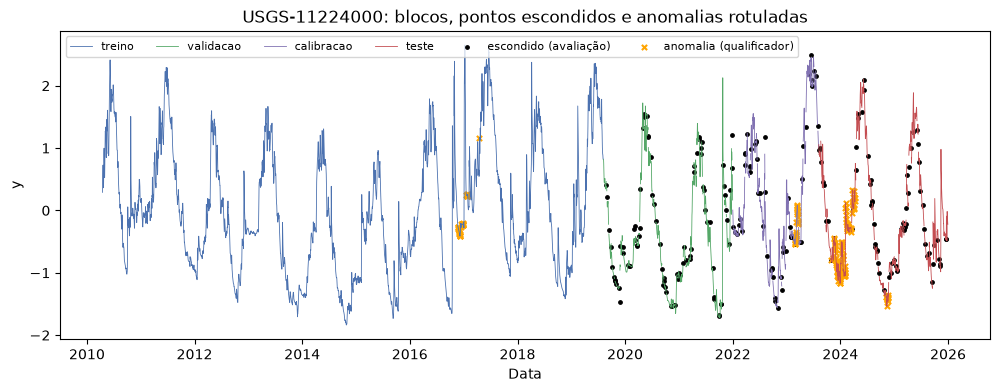

In [6]:
# sid = serie["sensor_id"].iloc[0]   # troque pelo ID de outra estação, se quiser
# estação com mais anomalias rotuladas no teste
sid = (serie[(serie["split"] == "teste") & (serie["anomalia"] == 1)]
       .groupby("sensor_id").size().idxmax())

s = serie[serie["sensor_id"] == sid]
fig, ax = plt.subplots(figsize=(12, 4))
colors = {"treino": "#4C72B0", "validacao": "#55A868", "calibracao": "#8172B2", "teste": "#C44E52"}
for name, g in s.groupby("split", sort=False):
    ax.plot(g["data"], g["y"].where(g["visivel"] == 1), lw=0.6, color=colors[name], label=name)
h = s[s["escondido_aval"] == 1]
ax.scatter(h["data"], h["y"], s=6, color="black", label="escondido (avaliação)")
a = s[s["anomalia"] == 1]
ax.scatter(a["data"], a["y"], s=14, marker="x", color="orange", label="anomalia (qualificador)")
ax.set(title=f"{sid}: blocos, pontos escondidos e anomalias rotuladas", xlabel="Data", ylabel="y")
ax.legend(ncol=6, fontsize=8, loc="upper left")
plt.show()

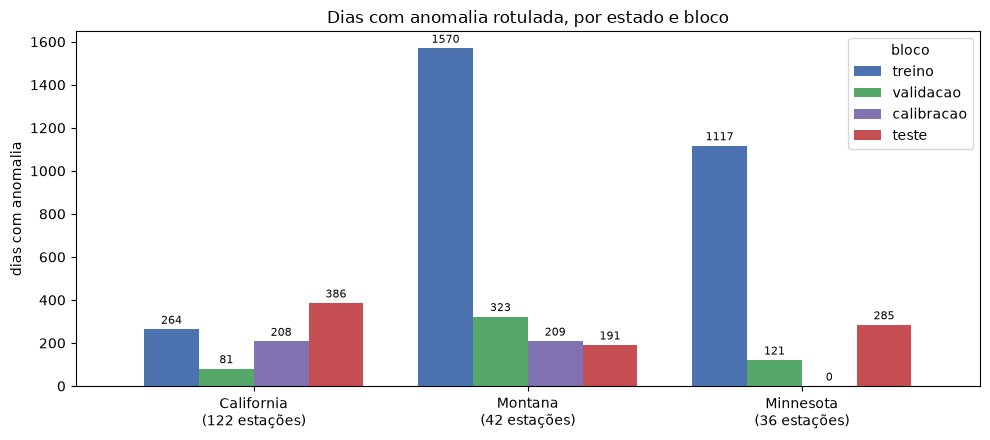

split,treino,validacao,calibracao,teste
California\n(122 estações),264,81,208,386
Montana\n(42 estações),1570,323,209,191
Minnesota\n(36 estações),1117,121,0,285


In [ ]:
ordem = ["treino", "validacao", "calibracao", "teste"]
cores = {"treino": "#4C72B0", "validacao": "#55A868", "calibracao": "#8172B2", "teste":  "#C44E52"}

# Estado de cada estação (vem da seleção feita no download)
estado = selected.set_index("monitoring_location_id")["state_name"]

# Dias com anomalia rotulada, por estado e bloco
anom = (serie[serie["anomalia"] == 1]
        .assign(estado=lambda d: d["sensor_id"].astype(str).map(estado))
        .groupby(["estado", "split"]).size()
        .unstack("split").reindex(columns=ordem).fillna(0).astype(int))

# Número de estações de cada estado na serie, para comparar estados de tamanhos diferentes
n_est = serie.groupby("sensor_id")["sensor_id"].first().astype(str).map(estado).value_counts()
anom = anom.reindex(n_est.index, fill_value=0)
anom.index = [f"{e}\n({n_est[e]} estações)" for e in anom.index]

ax = anom.plot.bar(color=[cores[s] for s in ordem], figsize=(10, 4.5), width=0.8, rot=0)
for c in ax.containers:
    ax.bar_label(c, fontsize=8, padding=2)   # valor em cima de cada barra
ax.set(title="Dias com anomalia rotulada, por estado e bloco", xlabel="", ylabel="dias com anomalia")
ax.legend(title="bloco")
plt.tight_layout()
plt.show()

display(anom)


In [ ]:
# A serie já está salva em data/exports/ pelo 02_serie_modelos.ipynb; não é preciso salvar aqui.

## 4. Entrada de cada modelo

As três funções partem da mesma `serie`. Nenhuma entrega NaN: o GP recebe só os dias visíveis; o RGP e o GPLVM recebem 0 nos dias sem valor visível, junto com uma máscara que manda ignorá-los.

**Papel de cada bloco, igual para os três modelos:**

| Bloco | O que o modelo faz | O que se mede |
|---|---|---|
| `treino` | ajusta os parâmetros (ELBO) só com os dias visíveis | nada |
| `validacao` | prevê com os parâmetros congelados | NLPD nos escondidos (objetivo da otimização Bayesiana) |
| `calibracao` | prevê com os parâmetros congelados | fator conformal e limiar de alerta |
| `teste` | prevê com os parâmetros congelados | métricas finais, uma única vez |

Fora do treino, o modelo pode **ler** os dias visíveis como entrada (o RGP lê a sequência; o GP condiciona nos dias visíveis), mas não reajusta nada com eles. Os dias escondidos nunca são lidos.

### 4.0 Vazão zero × o 0 colocado nas lacunas

O 0 que entra nas lacunas está na escala de `y` (log + padronização), não na escala da vazão.

| Caso | `y_bruto` | `y` | `visivel` | O modelo usa? |
|---|---|---|---|---|
| Vazão zero medida | 0.0 | `(log1p(0) − média) / desvio`, um valor negativo e grande | 1 | sim, é uma observação real |
| Lacuna (NaN ou escondido) | NaN ou valor escondido | 0 só na entrada, como preenchimento | 0 | não, a máscara manda ignorar |

O que separa os dois casos é a máscara, não o valor. O 0 de preenchimento corresponde à média da estação; a RNN do RGP recebe a máscara como segundo canal. No GP não há preenchimento.

Em escala log, um dia de vazão zero fica muito abaixo do normal e tende a receber escore alto, mesmo quando o rio secou de verdade. O filtro `max_zero_frac` exclui os rios intermitentes; nas estações que sobram, confira os alertas em dias de vazão zero.

In [9]:
display(stats.assign(y_de_vazao_zero=(np.log1p(0.0) - stats["mean"]) / stats["std"]).round(2))
print("dias com vazão zero na serie:", int((serie["y_bruto"] == 0).sum()))

,mean,std,y_de_vazao_zero
sensor_id,,,
USGS-04010500,5.65,1.04,-5.45
USGS-04021520,3.51,1.20,-2.93
USGS-05030500,6.08,0.59,-10.39
USGS-05061000,4.22,0.93,-4.56
USGS-05061500,4.02,1.23,-3.28
...,...,...,...
USGS-12365700,5.38,0.99,-5.43
USGS-12375900,2.79,0.83,-3.36
USGS-12381400,3.63,1.08,-3.37


dias com vazão zero na serie: 4144


### 4.1 Modelo 1: GP Student‑t

Uma estação por vez. A entrada do GP (`X`) é o tempo `t`; a saída (`Y`) é `y`.

| Variável | Conteúdo | Uso |
|---|---|---|
| `X_train`, `Y_train` | dias visíveis do treino | ajustar o modelo |
| `X_ctx`, `Y_ctx` | dias visíveis de todos os blocos | condicionar as previsões, com hiperparâmetros congelados |
| `X_val`, `X_cal`, `X_test` | todos os dias do bloco | onde prever e calcular o escore |
| `X_val_hid`, `Y_val_hid` (idem `cal`, `test`) | dias escondidos e seus valores verdadeiros | `X` para prever; `Y` **só para a métrica** |

In [10]:
gp = gp_inputs(serie, sensor_id=sid)

X_train, Y_train = gp["t_train"], gp["y_train"]
X_ctx, Y_ctx = gp["t_context"], gp["y_context"]

X_val, X_val_hid, Y_val_hid = (gp["splits"]["validacao"][k] for k in ("t_all", "t_hidden", "y_hidden"))
X_cal, X_cal_hid, Y_cal_hid = (gp["splits"]["calibracao"][k] for k in ("t_all", "t_hidden", "y_hidden"))
X_test, X_test_hid, Y_test_hid = (gp["splits"]["teste"][k] for k in ("t_all", "t_hidden", "y_hidden"))

for name in ("X_train", "Y_train", "X_ctx", "X_val", "X_val_hid", "X_cal", "X_cal_hid", "X_test", "X_test_hid"):
    v = globals()[name]
    print(f"{name:11s} {v.shape}  NaN: {np.isnan(v).any()}")

# No GPyTorch:
# import torch
# X_train_t = torch.tensor(X_train, dtype=torch.float32).unsqueeze(-1)   # (N, 1)
# Y_train_t = torch.tensor(Y_train, dtype=torch.float32)                 # (N,)
#
# Várias estações: um GP por estação
# for sid_i in serie["sensor_id"].unique():
#     gp_i = gp_inputs(serie, sensor_id=sid_i)
#     ...

X_train     (3401,)  NaN: False
Y_train     (3401,)  NaN: False
X_ctx       (5521,)  NaN: False
X_val       (877,)  NaN: False
X_val_hid   (87,)  NaN: False
X_cal       (584,)  NaN: False
X_cal_hid   (56,)  NaN: False
X_test      (877,)  NaN: False
X_test_hid  (75,)  NaN: False


#### Detalhes das variáveis do GP

Os números citados são de uma estação de exemplo; os da sua estação aparecem na célula acima.

**Como os dias dessa estação estão organizados**

A estação tem 5.844 dias (2010 a 2025), e cada dia cai num bloco:

```
2010 ─────────── treino ─────────── 2019 │ validacao │ calibracao │ teste 2025
```

Cada dia também tem um de três estados:

| Estado | O que é | O modelo pode ler? |
|---|---|---|
| **visível** | tem valor e não foi escondido | sim |
| **escondido** | tem valor, mas foi escondido de propósito (10% dos dias fora do treino) para testar a reconstrução | não, só a métrica usa |
| **faltante** | não tem valor (NaN) | não, não existe valor |

**Treino: o que ajusta o modelo**

```python
X_train, Y_train = gp["t_train"], gp["y_train"]
```

- `X_train`: os **dias** (o índice `t`: 0, 1, 2…) do treino que têm valor visível.
- `Y_train`: a **vazão** (`y`) nesses mesmos dias.
- Na estação de exemplo, são 3.506 pares (dia, vazão). É só com isso que o GP aprende os parâmetros.

**Contexto: o que o modelo pode "ver" depois de treinado**

```python
X_ctx, Y_ctx = gp["t_context"], gp["y_context"]
```

- São os dias visíveis de **todos** os blocos, e não só do treino: 5.612 dias na estação de exemplo.
- **Por que existe:** um GP prevê um dia olhando os dias vizinhos com valor. Para prever um dia de 2024, ajuda ver os dias de 2024 que têm valor. Isso é permitido porque **os parâmetros já estão congelados**: o modelo não reaprende nada com esses dias, só os usa como referência.
- Os dias escondidos nunca entram no contexto. Se entrassem, o modelo veria a resposta que vai ser cobrada.

**Validação, calibração e teste: onde prever e como avaliar**

```python
X_val, X_val_hid, Y_val_hid = (gp["splits"]["validacao"][k] for k in ("t_all", "t_hidden", "y_hidden"))
```

Essa linha cria três variáveis de uma vez. É o mesmo que escrever:

```python
X_val     = gp["splits"]["validacao"]["t_all"]     # todos os dias da validação (877)
X_val_hid = gp["splits"]["validacao"]["t_hidden"]  # só os dias escondidos (87)
Y_val_hid = gp["splits"]["validacao"]["y_hidden"]  # o valor verdadeiro desses 87 dias
```

| Variável | Para quê |
|---|---|
| `X_val` | dias onde o modelo **prevê e calcula o escore de anomalia** (todos os dias do bloco) |
| `X_val_hid` | dias onde o modelo **tenta reconstruir** um valor que foi escondido dele |
| `Y_val_hid` | o valor verdadeiro desses dias; **só serve para comparar** com a previsão (RMSE, cobertura). Nunca entra no modelo |

As linhas de `cal` (calibração) e `test` (teste) fazem exatamente o mesmo para os outros blocos.

### 4.2 Modelo 2: RGP‑t

Todas as estações juntas, como um lote de sequências ordenadas. A entrada `X` é a mesma em todos os blocos (a sequência inteira); o que muda de um bloco para outro é a máscara que diz quais dias contam.

| Variável | Formato | Uso |
|---|---|---|
| `X` | `(S, T, 2)` = [valor, máscara] | entrada da RNN de reconhecimento, em todos os blocos |
| `M_train` | `(S, T)` | dias que entram no ELBO (visíveis do treino) |
| `M_val`, `M_cal`, `M_test` | `(S, T)` | dias visíveis de cada bloco, onde se calcula o escore |
| `H_val`, `H_cal`, `H_test` | `(S, T)` | dias escondidos de cada bloco, onde se mede a reconstrução |
| `Y_true` | `(S, T)` | valores verdadeiros (NaN sem valor), **só para as métricas** |

In [11]:
rgp = rgp_inputs(serie)

X = rgp["rnn_in"]
M_train = rgp["fit_mask"]
M_val, M_cal, M_test = (rgp["split_masks"][b] for b in ("validacao", "calibracao", "teste"))
H_val, H_cal, H_test = (rgp["eval_masks"][b] for b in ("validacao", "calibracao", "teste"))
Y_true = rgp["y_true"]

print("estações (ordem das linhas):", rgp["sensors"])
print("X", X.shape, " NaN:", np.isnan(X).any())
for name in ("M_train", "M_val", "M_cal", "M_test", "H_val", "H_cal", "H_test"):
    print(f"{name:8s} dias marcados: {int(globals()[name].sum()):,}")

# No PyTorch:
# import torch
# X_t = torch.tensor(X, dtype=torch.float32)            # (S, T, 2)
# M_train_t = torch.tensor(M_train, dtype=torch.float32) # multiplica a log-verossimilhança de cada dia no ELBO

estações (ordem das linhas): ['USGS-04010500', 'USGS-04021520', 'USGS-05030500', 'USGS-05061000', 'USGS-05061500', 'USGS-05062000', 'USGS-05069000', 'USGS-05078230', 'USGS-05087500', 'USGS-05094000', 'USGS-05104500', 'USGS-05125000', 'USGS-05126210', 'USGS-05129115', 'USGS-05211000', 'USGS-05267000', 'USGS-05288580', 'USGS-05288705', 'USGS-05300000', 'USGS-05311000', 'USGS-05316500', 'USGS-05317000', 'USGS-05319500', 'USGS-05320000', 'USGS-05325000', 'USGS-05330000', 'USGS-05331000', 'USGS-05331580', 'USGS-05336700', 'USGS-05338500', 'USGS-05345000', 'USGS-05355200', 'USGS-05372995', 'USGS-05378500', 'USGS-05383950', 'USGS-05476000', 'USGS-06019500', 'USGS-06020600', 'USGS-06025500', 'USGS-06033000', 'USGS-06036650', 'USGS-06054500', 'USGS-06066500', 'USGS-06085800', 'USGS-06088500', 'USGS-06089000', 'USGS-06101500', 'USGS-06108000', 'USGS-06109500', 'USGS-06181000', 'USGS-06183450', 'USGS-06191000', 'USGS-06192500', 'USGS-06204050', 'USGS-06208500', 'USGS-06209500', 'USGS-06289000', '

### 4.3 Modelo 3: Bayesian GPLVM

Janelas sem sobreposição, montadas dentro de cada bloco (nunca atravessam dois blocos). No GPLVM a entrada `X` é latente (inferida pelo modelo); os dados observados são as janelas `Y`.

| Variável | Formato | Uso |
|---|---|---|
| `Y_train`, `M_train_w` | `(N, janela)` | ajustar o modelo (valores com 0 onde não há valor visível, e a máscara) |
| `Y_val`, `M_val_w` (idem `cal`, `test`) | `(N, janela)` | com os parâmetros congelados: inferir q(X) de cada janela e calcular o −ELBO (escore) |
| `Y_val_true`, `H_val_w` (idem `cal`, `test`) | `(N, janela)` | valores verdadeiros e células escondidas, **só para as métricas** |

In [12]:
JANELA = 7          # dias por janela (7 = semanal; 30 = mensal)
MAX_FALTANTE = 0.5  # descarta janelas com mais de 50% de células sem valor visível

gl = gplvm_inputs(serie, window=JANELA, max_missing=MAX_FALTANTE)
tr, va, ca, te = (select_split(gl, b) for b in ("treino", "validacao", "calibracao", "teste"))

Y_train, M_train_w = tr["Y"], tr["mask"]
Y_val, M_val_w, Y_val_true, H_val_w = va["Y"], va["mask"], va["Y_true"], va["hidden"]
Y_cal, M_cal_w, Y_cal_true, H_cal_w = ca["Y"], ca["mask"], ca["Y_true"], ca["hidden"]
Y_test, M_test_w, Y_test_true, H_test_w = te["Y"], te["mask"], te["Y_true"], te["hidden"]

for name in ("Y_train", "Y_val", "Y_cal", "Y_test"):
    v = globals()[name]
    print(f"{name:8s} {v.shape}  NaN: {np.isnan(v).any()}")

# Escore por janela -> por dia, no formato da saída:
# escore_dias = windows_to_days(te, elbo_negativo_por_janela_do_teste)

Y_train  (99928, 7)  NaN: False
Y_val    (24409, 7)  NaN: False
Y_cal    (16250, 7)  NaN: False
Y_test   (23442, 7)  NaN: False


## 5. Formato da saída dos modelos

Os três modelos devolvem a mesma tabela, uma linha por (estação, dia), na escala de `y`:

| Coluna | Significado |
|---|---|
| `sensor_id`, `t` | chave para cruzar com `serie` |
| `media` | previsão do modelo |
| `q025`, `q975` | intervalo de 95% |
| `escore` | quanto maior, mais anômalo; NaN nos dias sem valor visível |
| `logp` (opcional) | log da densidade preditiva do valor verdadeiro, para o NLPD |

Como cada modelo calcula o `escore`:

- **Modelos 1 e 2:** 1/E[τ], com E[τ] = (ν+1) / (ν + r), em que r = ((y − média)² + variância) / σ². Vale também nos dias de validação, calibração e teste, aplicando a fórmula à previsão do modelo.
- **Modelo 3:** −ELBO da janela, repetido em cada dia (`windows_to_days`).

A célula abaixo cria uma saída com um **modelo de referência** simples (média e desvio de cada dia do ano no treino). Ele não é um dos três modelos: serve para testar o formato e as métricas, e é a linha de base para comparar os resultados.

In [13]:
def climatology_baseline(serie):
    d = serie.assign(doy=serie["data"].dt.dayofyear.clip(upper=365))
    fit = d[(d["split"] == "treino") & (d["visivel"] == 1)]
    clim = fit.groupby(["sensor_id", "doy"])["y"].agg(media="mean", desvio="std").reset_index()
    clim["desvio"] = clim["desvio"].fillna(clim["desvio"].median())
    out = d[["sensor_id", "t", "doy", "y", "visivel"]].merge(clim, on=["sensor_id", "doy"], how="left")
    out["q025"] = out["media"] - 1.96 * out["desvio"]
    out["q975"] = out["media"] + 1.96 * out["desvio"]
    out["escore"] = ((out["y"] - out["media"]).abs() / out["desvio"]).where(out["visivel"] == 1)
    return out[OUTPUT_COLUMNS]

out = check_output(climatology_baseline(serie))   # troque pela saída do seu modelo
display(out.head())

,sensor_id,t,media,q025,q975,escore
0,USGS-04010500,0,-0.633162,-1.751837,0.485512,0.741541
1,USGS-04010500,1,-0.652837,-1.777094,0.471421,0.798242
2,USGS-04010500,2,-0.662428,-1.788074,0.463219,0.803157
3,USGS-04010500,3,-0.668882,-1.795312,0.457547,0.800869
4,USGS-04010500,4,-0.675516,-1.803174,0.452141,0.799925


## 6. Métricas

Duas avaliações separadas, sempre no bloco `teste`:

| Avaliação | Pergunta | Dias usados | Métricas |
|---|---|---|---|
| Previsão (reconstrução) | o modelo acerta o valor quando o dado falta? | `escondido_aval = 1` | RMSE, MAE, cobertura e largura do intervalo de 95%, interval score (NLPD se houver `logp`) |
| Detecção de anomalias | o modelo aponta os dias com problema? | `visivel = 1`, comparando `escore` com `anomalia` | AUC, average precision, recall no top 1%, precisão, recall e F1 |

### 6.1 Previsão (reconstrução)

- **RMSE / MAE:** erro médio da previsão nos dias escondidos.
- **Cobertura 95%:** fração dos valores verdadeiros dentro do intervalo; o ideal é perto de 0,95.
- **Largura média:** intervalos estreitos são melhores, desde que a cobertura se mantenha.
- **Interval score:** largura + penalidade quando o valor cai fora do intervalo; resume as duas coisas (menor é melhor).

In [14]:
display(pd.DataFrame({
    "escala y": reconstruction_metrics(serie, out, split="teste"),
    "ft³/s": reconstruction_metrics(serie, out, split="teste", stats=stats),
}))

,escala y,ft³/s
n,16305.000000,16305.000000
rmse,1.052755,2409.544376
mae,0.597691,542.979758
cobertura_95,0.893591,0.893591
largura_media,2.682307,4167.573608
interval_score,5.853274,5467.430869


### 6.2 Ajuste dos intervalos com conformal

O fator é calculado nos pontos escondidos da `calibracao` e depois aplicado aos intervalos. A cobertura no teste deve se aproximar de 95%. Como a série não é trocável no tempo, essa garantia é aproximada.

In [15]:
fator = conformal_factor(serie, out, alpha=0.05)
out_conf = apply_conformal(out, fator)
print(f"fator conformal: {fator:.3f}")
cols = ["cobertura_95", "largura_media", "interval_score"]
display(pd.DataFrame({
    "original": reconstruction_metrics(serie, out, "teste")[cols],
    "conformal": reconstruction_metrics(serie, out_conf, "teste")[cols],
}))

fator conformal: 1.401


,original,conformal
cobertura_95,0.893591,0.950383
largura_media,2.682307,3.758441
interval_score,5.853274,5.908706


### 6.3 Detecção de anomalias

1. O limiar de alerta vem da `calibracao` (percentil 99 dos escores), nunca do teste.
2. No teste, compara-se o `escore` com a coluna `anomalia`.

- **AUC:** chance de um dia anômalo ter escore maior que um dia normal (0,5 = acaso).
- **Average precision:** qualidade do ranking quando as anomalias são raras; compare com a `taxa_base`.
- **Recall no top 1%:** fração das anomalias rotuladas entre os 1% maiores escores.
- **Precisão, recall, F1:** dos alertas acima do limiar. A precisão é um limite inferior, porque há dias problemáticos sem rótulo.

In [16]:
limiar = threshold_from_calibration(serie, out, quantile=0.99)
display(detection_metrics(serie, out, limiar, split="teste").to_frame("teste"))

,teste
dias,148463.000000
anomalias,552.000000
taxa_base,0.003718
auc,0.386493
average_precision,0.003082
recall_top1%,0.027174
limiar,5.640393
alertas,2146.000000
precisao,0.009320
recall,0.036232


Recall por qualificador e AUC separada para dados aprovados e provisórios:

In [17]:
display(detection_by_group(serie, out, limiar, split="teste"))

,grupo,dias,recall,auc
0,qualificador Eqp,142,0.0,NaN
1,qualificador Ice,389,0.0,NaN
2,qualificador Mnt,1,0.0,NaN
3,qualificador Fld,20,1.0,NaN
4,Approved,144357,NaN,0.387166
5,Provisional,4106,NaN,NaN


## 7. Resumo do fluxo

1. Ler a `serie` salva pelo `02_serie_modelos.ipynb` (montada uma única vez com `SelectionConfig` e `SplitConfig`).
2. Gerar a entrada do seu modelo (seção 4): `gp_inputs`, `rgp_inputs` ou `gplvm_inputs`.
3. Ajustar o modelo só com o treino visível; escolher hiperparâmetros externos na `validacao`.
4. Devolver a saída no formato `OUTPUT_COLUMNS` para todos os dias.
5. Calcular limiar e fator conformal na `calibracao`.
6. Reportar as métricas no `teste`, uma única vez, junto com a linha de base climatológica.